# M4.2 · GARCH / DCC 动态协方差

> 协方差不是静止的：波动率存在聚集性（volatility clustering），资产间相关性也会在危机时上升。静态协方差无法刻画这种时变特征。
> 本节实现单变量 GARCH(1,1)（自实现 vs arch 库对照）与 Engle(2002) DCC 动态条件相关，得到随时间变化的协方差矩阵。

## 一、波动率聚集与 GARCH 思想

金融收益呈现「大波动跟着大波动、小波动跟着小波动」的聚集现象。GARCH(1,1) 用历史冲击和历史方差递推条件方差：

$$r_t=\sigma_t\varepsilon_t,\qquad \sigma_t^2=\omega+\alpha r_{t-1}^2+\beta\sigma_{t-1}^2$$

- $\omega>0$ 为长期均值项，$\alpha,\beta\ge 0$；
- **持续性** $\alpha+\beta<1$ 保证平稳，越接近 1 表示冲击衰减越慢；
- 无条件方差 $\bar\sigma^2=\omega/(1-\alpha-\beta)$。


## 二、自实现 GARCH(1,1) 与 arch 库对照

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from port_lab2 import garch
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$close'], start_time='2018-01-01', freq='day')
cl = raw['$close'].unstack('instrument')
ret = cl.pct_change(fill_method=None)
r1 = ret.iloc[:, 0].dropna()
f_self = garch.garch11_fit(r1)
f_arch = garch.garch_archlib(r1)
print('自实现: omega=%.7f alpha=%.4f beta=%.4f 持续性=%.4f'
      % (f_self['omega'], f_self['alpha'], f_self['beta'], f_self['persist']))
print('arch库: omega=%.7f alpha=%.4f beta=%.4f'
      % (f_arch['omega'], f_arch['alpha'], f_arch['beta']))
print('无条件方差(自实现) = %.7f, 样本方差 = %.7f'
      % (f_self['omega']/(1-f_self['persist']), np.var(r1)))

[11104:MainThread](2026-11-05 14:08:25,943) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[11104:MainThread](2026-11-05 14:08:27,914) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[11104:MainThread](2026-11-05 14:08:27,916) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


C:\Users\gucao\.conda\envs\qlib\lib\site-packages\scipy\optimize\_slsqp_py.py:435: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)


自实现: omega=0.0000134 alpha=0.0960 beta=0.8269 持续性=0.9229
arch库: omega=0.0000131 alpha=0.0955 beta=0.8290
无条件方差(自实现) = 0.0001732, 样本方差 = 0.0001644


## 三、条件波动率与多步预测

In [2]:
fcst = garch.garch11_forecast(r1, f_self, horizon=10)
print('未来 10 期条件方差预测:')
print(np.round(fcst, 6))
print('对应年化波动率: 起=%.3f 止=%.3f'
      % (np.sqrt(fcst[0]*242), np.sqrt(fcst[-1]*242)))

未来 10 期条件方差预测:
[0.000132 0.000135 0.000138 0.000141 0.000143 0.000146 0.000148 0.00015
 0.000151 0.000153]
对应年化波动率: 起=0.179 止=0.193


## 四、DCC 动态条件相关

单变量 GARCH 只给对角线。Engle(2002) DCC 两步法刻画时变相关：

1. **第一步**：逐资产 GARCH 得条件标准差 $D_t$ 与标准化残差 $z_t=D_t^{-1}r_t$；
2. **第二步**：动态伪相关 $Q_t=(1-a-b)\bar Q+a z_{t-1}z_{t-1}^\top+bQ_{t-1}$，再归一化 $R_t=\operatorname{diag}(Q_t)^{-1/2}Q_t\operatorname{diag}(Q_t)^{-1/2}$；
3. 动态协方差 $H_t=D_tR_tD_t$。

为控制计算量，取近 400 个交易日、8 只资产。

In [3]:
dcc = garch.dcc_fit(ret.iloc[-400:, :8].dropna(axis=1))
print('DCC 参数: a=%.4f b=%.4f 持续性=%.4f 收敛=%s'
      % (dcc['a'], dcc['b'], dcc['a']+dcc['b'], dcc['success']))
print('动态协方差 H 形状:', dcc['H'].shape)
print('首期 vs 末期 平均相关: %.4f vs %.4f'
      % (dcc['Rt'][0][np.triu_indices(8, 1)].mean(),
         dcc['Rt'][-1][np.triu_indices(8, 1)].mean()))

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\scipy\optimize\_slsqp_py.py:435: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)


DCC 参数: a=0.0446 b=0.9549 持续性=0.9995 收敛=True
动态协方差 H 形状: (400, 8, 8)
首期 vs 末期 平均相关: 0.3253 vs 0.2771


## 五、图表

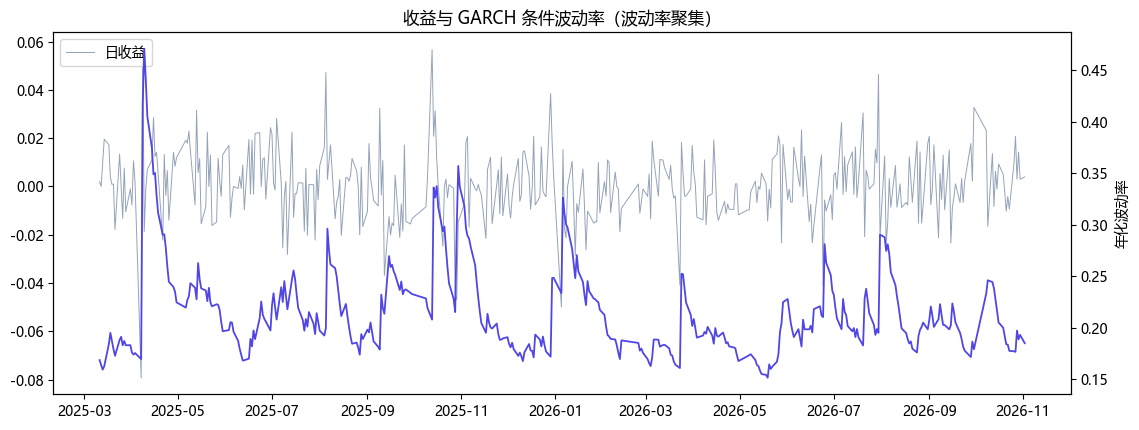

In [4]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(11.5, 4.4))
ax.plot(r1.index[-400:], r1.values[-400:], color='#94a3b8', lw=0.7, label='日收益')
ax2 = ax.twinx()
ax2.plot(r1.index[-400:], np.sqrt(f_self['sigma2'][-400:])*np.sqrt(242),
         color='#4f46e5', lw=1.3, label='GARCH年化波动率')
ax2.set_ylabel('年化波动率')
ax.set_title('收益与 GARCH 条件波动率（波动率聚集）'); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

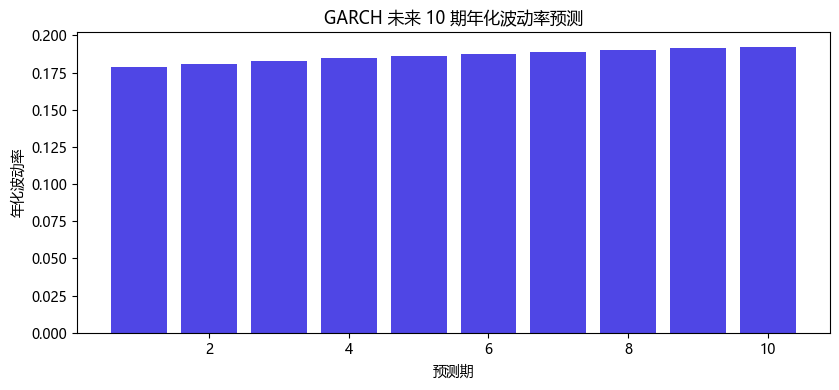

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.bar(np.arange(1, 11), np.sqrt(fcst*242), color='#4f46e5')
ax.set_title('GARCH 未来 10 期年化波动率预测'); ax.set_xlabel('预测期')
ax.set_ylabel('年化波动率')
plt.tight_layout(); plt.show()

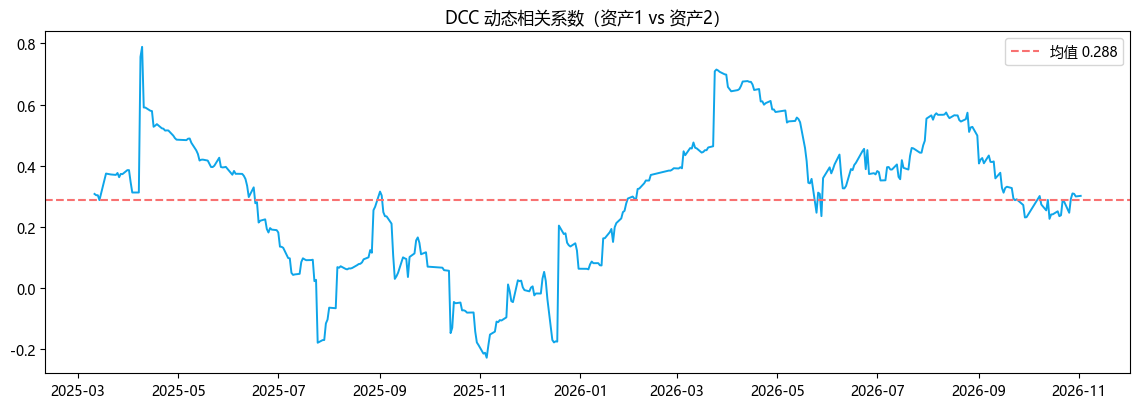

In [6]:
# 取前两只资产的动态相关
pair_corr = dcc['Rt'][:, 0, 1]
fig, ax = plt.subplots(figsize=(11.5, 4.2))
ax.plot(dcc['index'], pair_corr, color='#0ea5e9', lw=1.4)
ax.axhline(pair_corr.mean(), color='#f87171', ls='--', label='均值 %.3f' % pair_corr.mean())
ax.set_title('DCC 动态相关系数（资产1 vs 资产2）'); ax.legend()
plt.tight_layout(); plt.show()

C:\Users\gucao\AppData\Local\Temp\ipykernel_11104\756052808.py:6: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


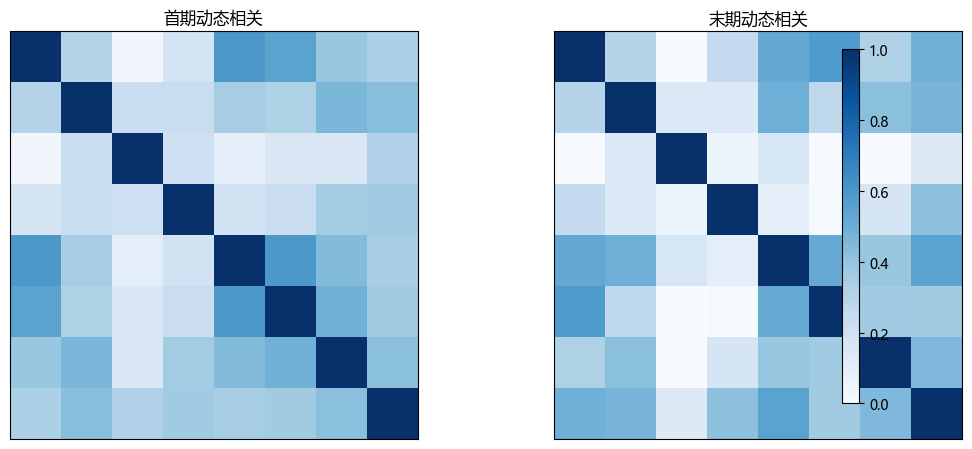

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, t, ttl in zip(axes, [0, -1], ['首期动态相关', '末期动态相关']):
    im = ax.imshow(dcc['Rt'][t], cmap='Blues', vmin=0, vmax=1)
    ax.set_title(ttl); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, fraction=0.03)
plt.tight_layout(); plt.show()

## 六、结论与适用条件

- **GARCH(1,1)** 用极少参数刻画波动率聚集，自实现（MLE）与 arch 库结果高度一致；持续性接近 1 说明 A 股波动冲击衰减较慢；
- **DCC** 在 GARCH 基础上刻画时变相关，危机时相关性上升可被捕捉，适合风险预算、对冲比率的动态调整；
- 局限：参数 DCC 假设相关由单一递推驱动，维度很高时计算昂贵；实务常用 DCC 思想 + 收缩/因子降维。

## 七、面试要点

- **GARCH(1,1) 各项含义与平稳条件？** $\omega$ 长期项、$\alpha$ 冲击、$\beta$ 记忆；$\alpha+\beta<1$ 平稳；
- **怎么估计 GARCH？** 高斯准极大似然（QMLE）+ 约束数值优化，即使非正态也一致；
- **DCC 两步法？** 先单变量 GARCH 标准化，再对标准化残差估计动态相关；
- **为什么需要动态协方差？** 波动率聚集、相关性随市场状态变化，静态矩阵低估危机风险；
- **DCC 的 $Q_t$ 与 $R_t$ 区别？** $Q_t$ 是伪相关（对角线不为 1），需归一化得相关矩阵 $R_t$。

## 动手练习
1. 拟合 GARCH(1,1)，报告 $\alpha,\beta$ 与持续性，计算无条件方差；
2. 做 10 期条件方差预测并年化；
3. 用 DCC 输出一对资产的动态相关序列并解释其变化。

---
下一节 M4.3 进入 Black-Litterman 模型。